# 03 — Simple CNN from scratch

**Q2. How much does a CNN that learns its own features improve over classical methods?**

A small CNN trained from scratch on split v2 (`src/models/simple_cnn.py`):

- **Architecture:** 4 blocks of (3×3 conv → BatchNorm → ReLU) × 2 → 2×2 max-pool, with 32 / 64 / 128 / 256 channels; then global average pooling → dropout 0.3 → linear layer to the 9 classes. 1.18M parameters.
- **Input:** 128×128 RGB, normalised with mean/std computed on the train split only.
- **Training:** Adam (lr 1e-3, weight decay 1e-4), cosine learning-rate decay over 30 epochs, batch size 64, cross-entropy loss. No augmentation or class weighting.
- **Model selection:** the checkpoint with the best validation macro F1 is kept; early stopping after 5 epochs without improvement.

This notebook reads the saved results. To re-train:

```bash
python -m src.train --config experiments/configs/simple_cnn.yaml
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path('..')
METRICS = ROOT / 'results' / 'metrics'
CM_DIR = ROOT / 'results' / 'confusion_matrices'
FIG_DIR = ROOT / 'results' / 'figures'
sns.set_theme(style='whitegrid')

KEYS = ['macro_f1', 'macro_precision', 'macro_recall', 'accuracy']


def load(run):
    return json.loads((METRICS / f'{run}.json').read_text())


def scores(runs, who='model'):
    """One row per run: val and test metrics from the saved results JSON."""
    rows = {}
    for name, r in runs.items():
        rows[name] = {f'{split} {k}': r['splits'][split][who][k]
                      for split in ('val', 'test') for k in KEYS}
    return pd.DataFrame(rows).T.round(3)


def per_class_f1(runs, split='test'):
    return pd.DataFrame({name: {c: m['f1'] for c, m in r['splits'][split]['model']['per_class'].items()}
                         for name, r in runs.items()}).round(3)

In [2]:
cnn = load('simple_cnn')
knn = load('knn_hist')
runs = {'KNN colour histogram': knn, 'Simple CNN': cnn}
print(f"parameters: {cnn['n_params']:,}, best epoch: {cnn['best_epoch']} of {len(cnn['history'])}, device: {cnn['device']}")
scores(runs)

parameters: 1,175,529, best epoch: 28 of 30, device: mps


,val macro_f1,val macro_precision,val macro_recall,val accuracy,test macro_f1,test macro_precision,test macro_recall,test accuracy
KNN colour histogram,0.406,0.442,0.394,0.524,0.452,0.493,0.437,0.581
Simple CNN,0.649,0.654,0.671,0.708,0.735,0.748,0.747,0.790


## 1. Training curves

at the best epoch: train accuracy 0.966, val macro F1 0.649


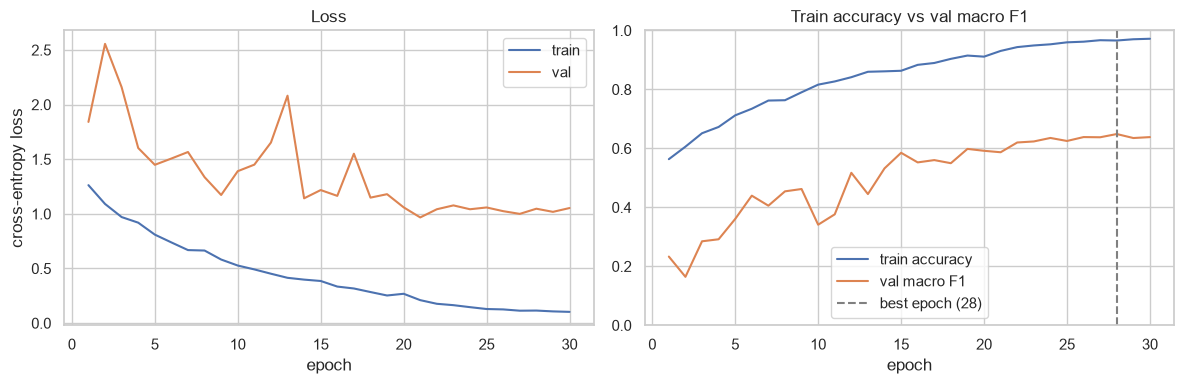

In [3]:
hist = pd.DataFrame(cnn['history'])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.plot(hist.epoch, hist.train_loss, label='train'); a.plot(hist.epoch, hist.val_loss, label='val')
a.set_xlabel('epoch'); a.set_ylabel('cross-entropy loss'); a.legend(); a.set_title('Loss')
b.plot(hist.epoch, hist.train_acc, label='train accuracy'); b.plot(hist.epoch, hist.val_macro_f1, label='val macro F1')
b.axvline(cnn['best_epoch'], color='grey', ls='--', label=f"best epoch ({cnn['best_epoch']})")
b.set_xlabel('epoch'); b.set_ylim(0, 1); b.legend(); b.set_title('Train accuracy vs val macro F1')
fig.tight_layout(); fig.savefig(FIG_DIR / 'cnn_training_curves.png', dpi=150)

best = hist.set_index('epoch').loc[cnn['best_epoch']]
print(f"at the best epoch: train accuracy {best.train_acc:.3f}, val macro F1 {best.val_macro_f1:.3f}")

## 2. Per-class test F1: CNN vs the best classical baseline

,KNN colour histogram,Simple CNN,gain
Prickly acacia,0.614,0.701,0.087
Negative,0.726,0.860,0.134
Lantana,0.517,0.779,0.262
Snake weed,0.319,0.608,0.289
Parkinsonia,0.525,0.820,0.295
Siam weed,0.588,0.901,0.313
Parthenium,0.211,0.549,0.338
Chinee apple,0.228,0.631,0.403
Rubber vine,0.344,0.765,0.421


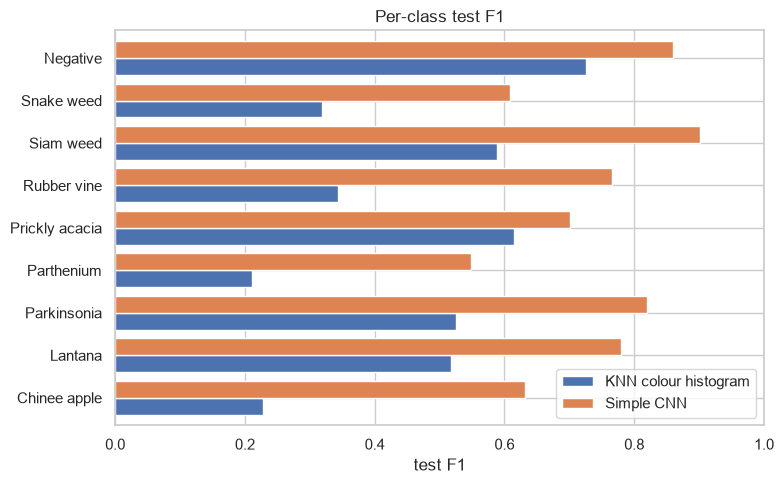

In [4]:
f1 = per_class_f1(runs)
f1['gain'] = f1['Simple CNN'] - f1['KNN colour histogram']
ax = f1.drop(columns='gain').plot.barh(figsize=(8, 5), width=0.8)
ax.set_xlabel('test F1'); ax.set_xlim(0, 1); ax.set_title('Per-class test F1')
ax.figure.tight_layout(); ax.figure.savefig(FIG_DIR / 'cnn_per_class_f1.png', dpi=150)
f1.sort_values('gain')

## 3. Confusion matrix (test, row-normalised)

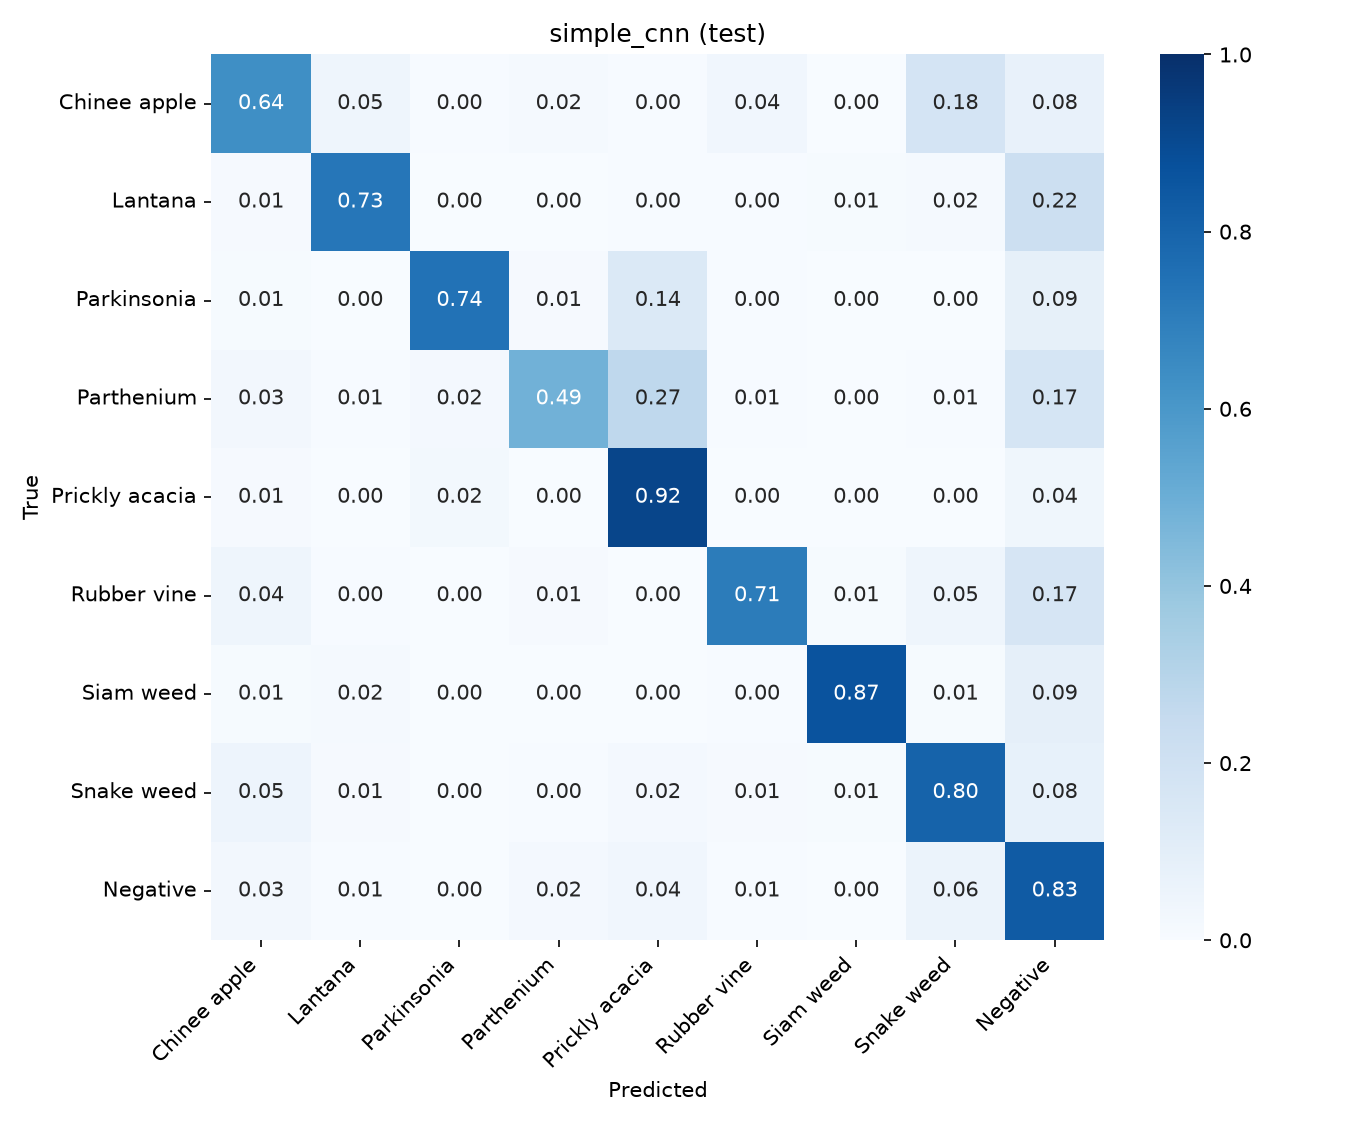

Negative -> Snake weed: 113
Negative -> Prickly acacia: 68
Negative -> Chinee apple: 50
Lantana -> Negative: 47
Parthenium -> Prickly acacia: 47


In [5]:
display(Image(CM_DIR / 'simple_cnn_test.png', width=600))
for t, p, n in cnn['top_confusions_test']:
    print(f'{t} -> {p}: {n}')

## Takeaways

- **Learned features beat hand-made ones by a wide margin.** Test macro F1 rises from 0.452 (KNN colour histogram) to 0.735, +0.28. Every class improves; the biggest gains are Rubber vine (+0.42), Chinee apple (+0.40) and Parthenium (+0.34).
- **The model overfits.** At the best epoch it gets 96.6% of training images right, but validation macro F1 is only 0.649. Regularisation, starting with augmentation, is the natural next step.
- **Gains come late.** Validation macro F1 is noisy while the learning rate is high and climbs steadily once the cosine schedule brings it down: the best epoch is 28 of 30.
- **The errors have flipped since the KNN.** The CNN now mostly predicts weeds where there are none (*Negative* → Snake weed 113, *Negative* → Prickly acacia 68) rather than missing weeds. Parthenium (0.549) and Snake weed (0.608) are the weakest classes.
- **Test is higher than validation** (0.735 against 0.649). The KNN shows the same gap (0.452 against 0.406), so split v2's validation set is simply harder; compare models on the same split rather than across val and test.

**Answer to Q2:** a small CNN trained from scratch improves test macro F1 by 0.28 over the best classical method, to 0.735.